# Maternal Mortality Ratio Statistical Analysis
## World Bank Dataset (API_SH.STA.MMRT_DS2)

This notebook presents comprehensive statistical analysis of global Maternal Mortality Ratio (MMR) data from 1960-2025, including:
- Descriptive statistics and data exploration
- Inferential statistical tests
- Temporal trend analysis
- Regional comparisons
- Visualizations and charts

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [2]:
# Load and parse the Maternal Mortality Ratio dataset
file_path = r'c:\Users\akpor\Downloads\Analysis\API_SH.STA.MMRT_DS2_en_excel_v2_1302.xls'

# Read the raw Excel file
df_raw = pd.read_excel(file_path, header=None)

# Parse the structure: Row 3 contains headers, data starts from row 4
header_row_idx = 3
data_start_row = 4
year_col_start = 4

# Extract years from the header
years = df_raw.iloc[header_row_idx, year_col_start:].values
years = [int(float(y)) if pd.notna(y) else None for y in years]
years = [y for y in years if y is not None]

# Extract countries and country codes
countries = df_raw.iloc[data_start_row:, 0].values
country_codes = df_raw.iloc[data_start_row:, 1].values

# Extract data values
data_values = df_raw.iloc[data_start_row:, year_col_start:year_col_start+len(years)].values
data_values = data_values.astype(float)

# Create the main DataFrame
mmr_data = pd.DataFrame(
    data=data_values,
    columns=[str(y) for y in years],
    index=countries
)

# Add a country code column for reference
mmr_data['Country_Code'] = country_codes
mmr_data = mmr_data.set_index('Country_Code', append=True)

print("Dataset loaded successfully!")
print(f"Shape: {mmr_data.shape}")
print(f"Countries/Regions: {len(mmr_data)}")
print(f"Years: {len(years)} ({min(years)} - {max(years)})")
print(f"\nFirst 10 rows and columns:")
print(mmr_data.iloc[:10, :10])

Dataset loaded successfully!
Shape: (266, 66)
Countries/Regions: 266
Years: 66 (1960 - 2025)

First 10 rows and columns:
                                          1960  1961  1962  1963  1964  1965  \
                            Country_Code                                       
Aruba                       ABW            NaN   NaN   NaN   NaN   NaN   NaN   
Africa Eastern and Southern AFE            NaN   NaN   NaN   NaN   NaN   NaN   
Afghanistan                 AFG            NaN   NaN   NaN   NaN   NaN   NaN   
Africa Western and Central  AFW            NaN   NaN   NaN   NaN   NaN   NaN   
Angola                      AGO            NaN   NaN   NaN   NaN   NaN   NaN   
Albania                     ALB            NaN   NaN   NaN   NaN   NaN   NaN   
Andorra                     AND            NaN   NaN   NaN   NaN   NaN   NaN   
Arab World                  ARB            NaN   NaN   NaN   NaN   NaN   NaN   
United Arab Emirates        ARE            NaN   NaN   NaN   NaN   NaN   NaN   

## 1. Data Exploration and Missing Data Analysis

In [3]:
# Missing data analysis
mmr_numeric = mmr_data.iloc[:, :-1]  # Exclude Country_Code column

# Calculate missing data statistics
missing_per_year = mmr_numeric.isnull().sum()
missing_per_country = mmr_numeric.isnull().sum(axis=1)
missing_percentage = (missing_per_country / len(mmr_numeric.columns)) * 100

print("=" * 70)
print("MISSING DATA ANALYSIS")
print("=" * 70)

print("\nMissing values per year (first and last 10 years):")
print(missing_per_year.head(10))
print("...")
print(missing_per_year.tail(10))

print(f"\n\nTotal missing values: {mmr_numeric.isnull().sum().sum()}")
print(f"Overall missing percentage: {(mmr_numeric.isnull().sum().sum() / mmr_numeric.size) * 100:.2f}%")

print("\n\nCountries with most data completeness (top 10):")
complete_data = mmr_numeric.dropna(axis=0, how='any')
print(f"Countries with complete data (no missing values): {len(complete_data)}")

print("\nTop 10 countries by data completeness:")
completeness = ((len(mmr_numeric.columns) - missing_per_country) / len(mmr_numeric.columns)) * 100
completeness_df = pd.DataFrame({'Country': completeness.index, 'Completeness_%': completeness.values})
print(completeness_df.nlargest(10, 'Completeness_%').to_string(index=False))

MISSING DATA ANALYSIS

Missing values per year (first and last 10 years):
1960    266
1961    266
1962    266
1963    266
1964    266
1965    266
1966    266
1967    266
1968    266
1969    266
dtype: int64
...
2015     24
2016     24
2017     24
2018     24
2019     24
2020     24
2021     24
2022     24
2023     24
2024    266
dtype: int64


Total missing values: 7852
Overall missing percentage: 45.41%


Countries with most data completeness (top 10):
Countries with complete data (no missing values): 0

Top 10 countries by data completeness:
                           Country  Completeness_%
(Africa Eastern and Southern, AFE)            60.0
                (Afghanistan, AFG)            60.0
 (Africa Western and Central, AFW)            60.0
                     (Angola, AGO)            60.0
                    (Albania, ALB)            60.0
                    (Andorra, AND)            60.0
                 (Arab World, ARB)            60.0
       (United Arab Emirates, ARE)        

## 2. Descriptive Statistics - Overall Summary

In [4]:
# Descriptive statistics for all data
all_mmr_values = mmr_numeric.values.flatten()
all_mmr_values = all_mmr_values[~np.isnan(all_mmr_values)]

print("=" * 70)
print("DESCRIPTIVE STATISTICS - ALL MATERNAL MORTALITY RATIO VALUES")
print("=" * 70)
print(f"\nCount: {len(all_mmr_values)}")
print(f"Mean: {np.mean(all_mmr_values):.2f}")
print(f"Median: {np.median(all_mmr_values):.2f}")
print(f"Mode: {stats.mode(all_mmr_values, keepdims=True).mode[0]:.2f}")
print(f"Standard Deviation: {np.std(all_mmr_values):.2f}")
print(f"Variance: {np.var(all_mmr_values):.2f}")
print(f"Minimum: {np.min(all_mmr_values):.2f}")
print(f"Maximum: {np.max(all_mmr_values):.2f}")
print(f"Range: {np.max(all_mmr_values) - np.min(all_mmr_values):.2f}")
print(f"Q1 (25th percentile): {np.percentile(all_mmr_values, 25):.2f}")
print(f"Q3 (75th percentile): {np.percentile(all_mmr_values, 75):.2f}")
print(f"IQR: {np.percentile(all_mmr_values, 75) - np.percentile(all_mmr_values, 25):.2f}")
print(f"Skewness: {stats.skew(all_mmr_values):.4f}")
print(f"Kurtosis: {stats.kurtosis(all_mmr_values):.4f}")

# Summary statistics by year
print("\n" + "=" * 70)
print("SUMMARY STATISTICS BY YEAR (Latest 10 years with data)")
print("=" * 70)
stats_by_year = mmr_numeric.describe().T
stats_by_year = stats_by_year.iloc[-10:, :]
print(stats_by_year.to_string())

DESCRIPTIVE STATISTICS - ALL MATERNAL MORTALITY RATIO VALUES

Count: 9438
Mean: 245.80
Median: 86.00
Mode: 7.00
Standard Deviation: 384.23
Variance: 147635.84
Minimum: 1.00
Maximum: 8045.00
Range: 8044.00
Q1 (25th percentile): 22.00
Q3 (75th percentile): 342.00
IQR: 320.00
Skewness: 5.8863
Kurtosis: 80.5697

SUMMARY STATISTICS BY YEAR (Latest 10 years with data)
      count        mean         std  min    25%   50%     75%     max
2015  242.0  167.772727  231.812259  1.0  15.00  70.0  222.00  1436.0
2016  242.0  161.165289  227.997501  1.0  15.00  67.0  214.00  1629.0
2017  242.0  155.917355  224.855309  1.0  15.25  63.0  200.00  1662.0
2018  242.0  147.190083  198.533872  1.0  14.25  66.0  198.75  1118.0
2019  242.0  144.896694  207.654801  1.0  14.25  65.0  190.75  1650.0
2020  242.0  145.293388  192.167784  2.0  20.00  74.0  194.00  1296.0
2021  242.0  162.533058  189.813976  2.0  25.25  98.0  218.25  1127.0
2022  242.0  134.549587  171.272197  1.0  17.00  71.5  181.75  1016.0
2023 

In [5]:
# Categorize MMR into risk levels for frequency analysis
# Using WHO/World Bank guidelines
latest_year = '2023'
mmr_2023 = mmr_numeric[latest_year].dropna()
mmr_2023_index = mmr_2023.index

def categorize_mmr(value):
    if value < 20:
        return 'Very Low (<20)'
    elif value < 100:
        return 'Low (20-99)'
    elif value < 300:
        return 'Medium (100-299)'
    elif value < 750:
        return 'High (300-749)'
    else:
        return 'Very High (≥750)'

mmr_2023_categories = mmr_2023.apply(categorize_mmr)
category_counts = mmr_2023_categories.value_counts()
category_percentages = (category_counts / len(mmr_2023) * 100).round(2)

print("\n" + "=" * 70)
print("FREQUENCY DISTRIBUTION - MMR RISK CATEGORIES (2023)")
print("=" * 70)
print(f"\n{'Risk Level':<20} {'Count':<10} {'Percentage':<10}")
print("-" * 40)
for category in ['Very Low (<20)', 'Low (20-99)', 'Medium (100-299)', 'High (300-749)', 'Very High (≥750)']:
    if category in category_counts.index:
        count = category_counts[category]
        pct = category_percentages[category]
        print(f"{category:<20} {count:<10} {pct:.1f}%")

# Top 10 countries with highest MMR in 2023
print("\n" + "=" * 70)
print("TOP 10 COUNTRIES WITH HIGHEST MMR (2023)")
print("=" * 70)
top_10 = mmr_2023.nlargest(10)
for i, (idx, value) in enumerate(top_10.items(), 1):
    # Handle both single string and tuple indices
    if isinstance(idx, tuple):
        country_name = idx[0]
    else:
        country_name = idx
    print(f"{i:2}. {country_name:<35} {value:>6.0f}")

# Top 10 countries with lowest MMR in 2023
print("\n" + "=" * 70)
print("TOP 10 COUNTRIES WITH LOWEST MMR (2023)")
print("=" * 70)
bottom_10 = mmr_2023.nsmallest(10)
for i, (idx, value) in enumerate(bottom_10.items(), 1):
    # Handle both single string and tuple indices
    if isinstance(idx, tuple):
        country_name = idx[0]
    else:
        country_name = idx
    print(f"{i:2}. {country_name:<35} {value:>6.0f}")


FREQUENCY DISTRIBUTION - MMR RISK CATEGORIES (2023)

Risk Level           Count      Percentage
----------------------------------------
Very Low (<20)       82         33.9%
Low (20-99)          70         28.9%
Medium (100-299)     57         23.6%
High (300-749)       32         13.2%
Very High (≥750)     1          0.4%

TOP 10 COUNTRIES WITH HIGHEST MMR (2023)
 1. Nigeria                                993
 2. Chad                                   748
 3. Central African Republic               692
 4. South Sudan                            692
 5. Africa Western and Central             650
 6. Liberia                                628
 7. Somalia, Fed. Rep.                     563
 8. Afghanistan                            521
 9. Benin                                  518
10. Guinea-Bissau                          505

TOP 10 COUNTRIES WITH LOWEST MMR (2023)
 1. Belarus                                  1
 2. Norway                                   1
 3. Australia             

## 3. Data Visualization - Distributions and Trends

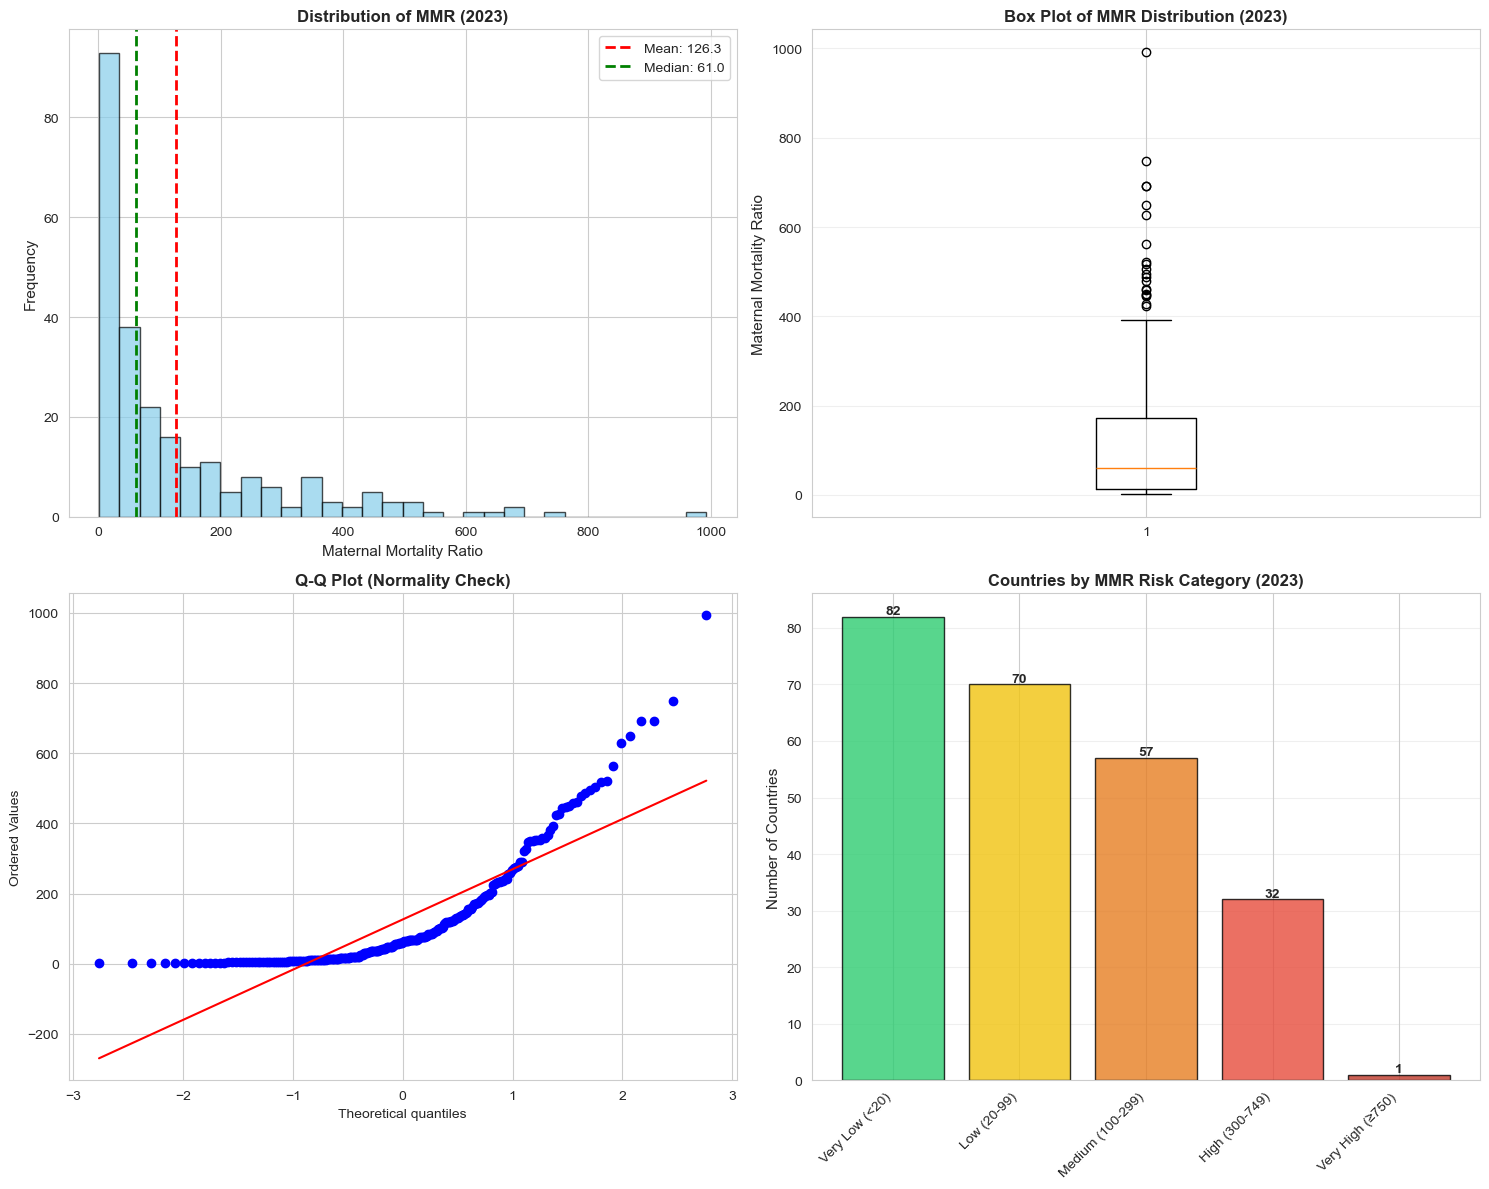

Visualizations created successfully!


In [19]:
# Visualization 1: Distribution of MMR values (2023)
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Histogram
axes[0, 0].hist(mmr_2023, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_xlabel('Maternal Mortality Ratio', fontsize=11)
axes[0, 0].set_ylabel('Frequency', fontsize=11)
axes[0, 0].set_title('Distribution of MMR (2023)', fontsize=12, fontweight='bold')
axes[0, 0].axvline(mmr_2023.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {mmr_2023.mean():.1f}')
axes[0, 0].axvline(mmr_2023.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {mmr_2023.median():.1f}')
axes[0, 0].legend()

# Box plot
axes[0, 1].boxplot(mmr_2023, vert=True)
axes[0, 1].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[0, 1].set_title('Box Plot of MMR Distribution (2023)', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)

# Q-Q Plot
stats.probplot(mmr_2023, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Normality Check)', fontsize=12, fontweight='bold')

# Category frequency bar chart
category_order = ['Very Low (<20)', 'Low (20-99)', 'Medium (100-299)', 'High (300-749)', 'Very High (≥750)']
category_counts_ordered = [category_counts.get(cat, 0) for cat in category_order]
colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#c0392b']
axes[1, 1].bar(range(len(category_order)), category_counts_ordered, color=colors, edgecolor='black', alpha=0.8)
axes[1, 1].set_xticks(range(len(category_order)))
axes[1, 1].set_xticklabels(category_order, rotation=45, ha='right')
axes[1, 1].set_ylabel('Number of Countries', fontsize=11)
axes[1, 1].set_title('Countries by MMR Risk Category (2023)', fontsize=12, fontweight='bold')
axes[1, 1].grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, v in enumerate(category_counts_ordered):
    axes[1, 1].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("Visualizations created successfully!")

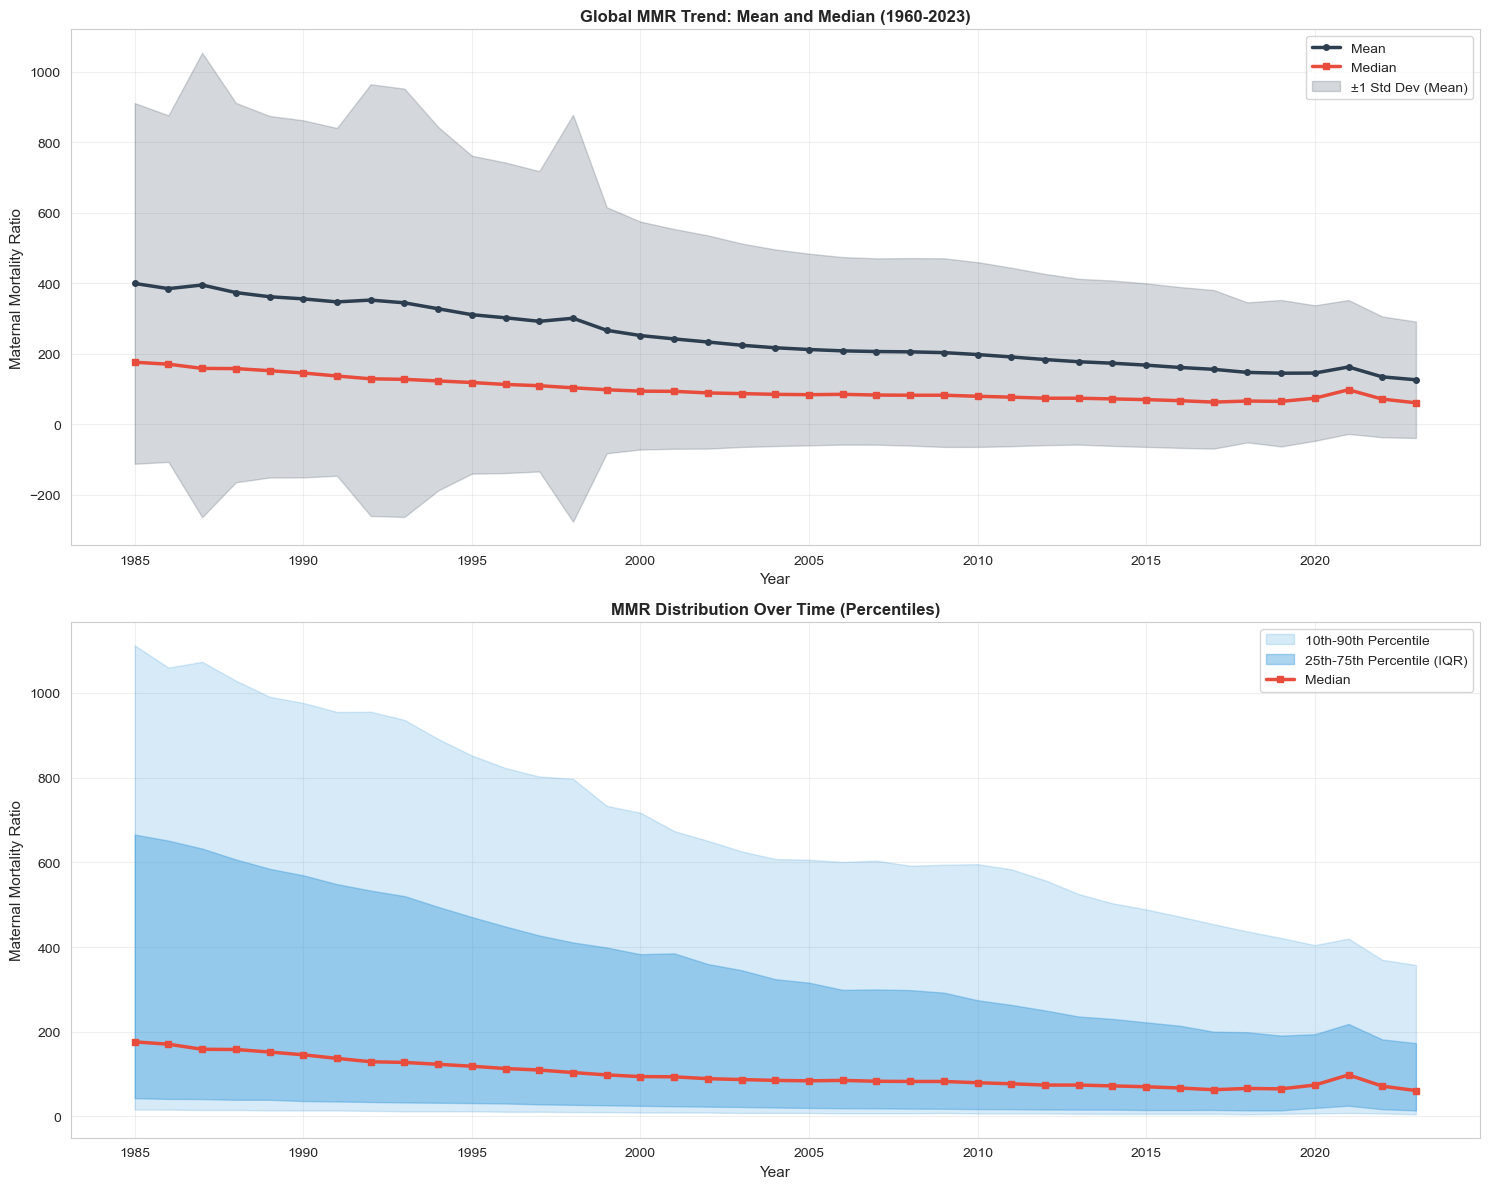

Trend analysis complete!


In [20]:
# Visualization 2: Global MMR Trends Over Time
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# Calculate statistics by year
years_numeric = mmr_numeric.columns.astype(int)
mean_mmr = mmr_numeric.mean()
median_mmr = mmr_numeric.median()
std_mmr = mmr_numeric.std()

# Trend plot 1: Mean and Median with confidence interval
axes[0].plot(years_numeric, mean_mmr, marker='o', linewidth=2.5, label='Mean', color='#2c3e50', markersize=4)
axes[0].plot(years_numeric, median_mmr, marker='s', linewidth=2.5, label='Median', color='#e74c3c', markersize=4)
axes[0].fill_between(years_numeric, mean_mmr - std_mmr, mean_mmr + std_mmr, alpha=0.2, color='#2c3e50', label='±1 Std Dev (Mean)')
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[0].set_title('Global MMR Trend: Mean and Median (1960-2023)', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Trend plot 2: Percentiles
p10 = mmr_numeric.quantile(0.1)
p25 = mmr_numeric.quantile(0.25)
p75 = mmr_numeric.quantile(0.75)
p90 = mmr_numeric.quantile(0.9)

axes[1].fill_between(years_numeric, p10, p90, alpha=0.2, color='#3498db', label='10th-90th Percentile')
axes[1].fill_between(years_numeric, p25, p75, alpha=0.4, color='#3498db', label='25th-75th Percentile (IQR)')
axes[1].plot(years_numeric, median_mmr, color='#e74c3c', linewidth=2.5, marker='s', label='Median', markersize=4)
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[1].set_title('MMR Distribution Over Time (Percentiles)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Trend analysis complete!")

## 4. Inferential Statistics - Correlation and Trend Analysis

In [19]:
# Correlation analysis between years
print("=" * 70)
print("CORRELATION ANALYSIS - TIME SERIES")
print("=" * 70)

# Correlation between consecutive decades
correlation_matrix_decades = mmr_numeric.iloc[:, ::10].corr()  # Every 10 years
print("\n\nCorrelation Matrix - Every 10 Years:")
print(correlation_matrix_decades.to_string())

# Calculate trend correlation (Year vs MMR values)
# For each country, calculate correlation between year index and MMR values
trends = []
for country in mmr_numeric.index:
    values = mmr_numeric.loc[country].values
    years_array = np.arange(len(values))
    
    # Remove NaN values for this country
    valid_idx = ~np.isnan(values)
    if valid_idx.sum() > 1:  # Need at least 2 points
        valid_years = years_array[valid_idx]
        valid_values = values[valid_idx]
        
        corr, pval = pearsonr(valid_years, valid_values)
        trends.append({
            'Country': country,
            'Correlation': corr,
            'P-Value': pval,
            'Significance': 'Yes' if pval < 0.05 else 'No',
            'Trend': 'Declining' if corr < 0 else 'Increasing'
        })

trends_df = pd.DataFrame(trends)

print("\n" + "=" * 70)
print("INDIVIDUAL COUNTRY TRENDS (Year vs MMR)")
print("=" * 70)

# Countries with significant declining trends (improvement)
declining_sig = trends_df[(trends_df['Trend'] == 'Declining') & (trends_df['Significance'] == 'Yes')].sort_values('Correlation')
print(f"\n\nCountries with SIGNIFICANT DECLINING MMR (Improvement):")
print(f"Top 10 countries with steepest improvement:\n")
print(declining_sig.head(10)[['Country', 'Correlation', 'P-Value']].to_string(index=False))

# Countries with significant increasing trends (worsening)
increasing_sig = trends_df[(trends_df['Trend'] == 'Increasing') & (trends_df['Significance'] == 'Yes')].sort_values('Correlation', ascending=False)
print(f"\n\nCountries with SIGNIFICANT INCREASING MMR (Worsening):")
if len(increasing_sig) > 0:
    print(increasing_sig.head(10)[['Country', 'Correlation', 'P-Value']].to_string(index=False))
else:
    print("No countries with significant increasing trend")

# Overall statistics
print("\n" + "=" * 70)
print("SUMMARY STATISTICS OF TRENDS")
print("=" * 70)
print(f"Countries with significant declining trend: {len(declining_sig)} ({len(declining_sig)/len(trends_df)*100:.1f}%)")
print(f"Countries with significant increasing trend: {len(increasing_sig)} ({len(increasing_sig)/len(trends_df)*100:.1f}%)")
print(f"Mean trend correlation: {trends_df['Correlation'].mean():.4f}")
print(f"Median trend correlation: {trends_df['Correlation'].median():.4f}")

CORRELATION ANALYSIS - TIME SERIES


Correlation Matrix - Every 10 Years:
      1960  1970  1980      1990      2000      2010      2020
1960   NaN   NaN   NaN       NaN       NaN       NaN       NaN
1970   NaN   NaN   NaN       NaN       NaN       NaN       NaN
1980   NaN   NaN   NaN       NaN       NaN       NaN       NaN
1990   NaN   NaN   NaN  1.000000  0.895987  0.772417  0.753305
2000   NaN   NaN   NaN  0.895987  1.000000  0.917309  0.893060
2010   NaN   NaN   NaN  0.772417  0.917309  1.000000  0.931991
2020   NaN   NaN   NaN  0.753305  0.893060  0.931991  1.000000

INDIVIDUAL COUNTRY TRENDS (Year vs MMR)


Countries with SIGNIFICANT DECLINING MMR (Improvement):
Top 10 countries with steepest improvement:

                                        Country  Correlation      P-Value
                                  (Guinea, GIN)    -0.999008 1.300789e-51
                                (Ethiopia, ETH)    -0.995702 7.637755e-40
                                 (Lao PDR, LAO)    -0.99

In [6]:
# Shared analysis windows limited to the valid data span
analysis_years = [year for year in mmr_numeric.columns if 1985 <= int(year) <= 2023]
late_20th_years = [year for year in analysis_years if int(year) <= 1999]
twenty_first_years = [year for year in analysis_years if int(year) >= 2000]

late_20th_values = mmr_numeric[late_20th_years].values.flatten()
late_20th_values = late_20th_values[~np.isnan(late_20th_values)]

twenty_first_values = mmr_numeric[twenty_first_years].values.flatten()
twenty_first_values = twenty_first_values[~np.isnan(twenty_first_values)]

analysis_period_labels = ['Late 20th Century (1985-1999)', '21st Century (2000-2023)']

print("Analysis window set to 1985-2023")
print(f"Late 20th century: {late_20th_years[0]}-{late_20th_years[-1]} ({len(late_20th_values)} observations)")
print(f"21st century: {twenty_first_years[0]}-{twenty_first_years[-1]} ({len(twenty_first_values)} observations)")

Analysis window set to 1985-2023
Late 20th century: 1985-1999 (3630 observations)
21st century: 2000-2023 (5808 observations)


In [7]:
# Chi-Square Test: Association between Risk Categories and Time Periods
print("\n" + "=" * 70)
print("CHI-SQUARE TEST - ASSOCIATION ANALYSIS")
print("=" * 70)

# Build a 2-period contingency table over the valid data span only
period_risk_data = []
for year_col in analysis_years:
    year_values = mmr_numeric[year_col].dropna()
    year_categories = year_values.apply(categorize_mmr)
    period = analysis_period_labels[0] if int(year_col) <= 1999 else analysis_period_labels[1]

    for _, risk in year_categories.items():
        period_risk_data.append({'Period': period, 'Risk_Category': risk, 'Count': 1})

period_risk_df = pd.DataFrame(period_risk_data)
contingency_table = pd.crosstab(period_risk_df['Period'], period_risk_df['Risk_Category'])

print("\n\nContingency Table - Late 20th Century vs 21st Century:")
print(contingency_table.to_string())

# Perform chi-square test
chi2, p_value, dof, expected_freq = chi2_contingency(contingency_table)

print(f"\n\nChi-Square Test Results:")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p_value:.4e}")
print(f"Degrees of Freedom: {dof}")
print(f"Interpretation: {'Significant association' if p_value < 0.05 else 'No significant association'} between period and MMR risk category (α = 0.05)")

# Expected frequencies
print(f"\n\nExpected Frequencies:")
expected_df = pd.DataFrame(expected_freq,
                          index=contingency_table.index,
                          columns=contingency_table.columns)
print(expected_df.round(2).to_string())


CHI-SQUARE TEST - ASSOCIATION ANALYSIS


Contingency Table - Late 20th Century vs 21st Century:
Risk_Category                  High (300-749)  Low (20-99)  Medium (100-299)  Very High (≥750)  Very Low (<20)
Period                                                                                                        
21st Century (2000-2023)                 1076         1736              1224               214            1558
Late 20th Century (1985-1999)             711         1032               639               596             652


Chi-Square Test Results:
Chi-Square Statistic: 513.6086
P-Value: 7.6312e-110
Degrees of Freedom: 4
Interpretation: Significant association between period and MMR risk category (α = 0.05)


Expected Frequencies:
Risk_Category                  High (300-749)  Low (20-99)  Medium (100-299)  Very High (≥750)  Very Low (<20)
Period                                                                                                        
21st Century (2000-2023)

In [8]:
# T-Tests: Comparing MMR between the late 20th century and the 21st century
print("\n" + "=" * 70)
print("T-TESTS - COMPARING MMR BETWEEN PERIODS")
print("=" * 70)

# Perform independent samples t-tests on the valid data span only
print(f"\n1. T-Test: {analysis_period_labels[0]} vs {analysis_period_labels[1]}")
t_stat, p_val = stats.ttest_ind(late_20th_values, twenty_first_values, equal_var=False)
print(f"   Mean ({analysis_period_labels[0]}): {late_20th_values.mean():.2f}")
print(f"   Mean ({analysis_period_labels[1]}): {twenty_first_values.mean():.2f}")
print(f"   T-Statistic: {t_stat:.4f}")
print(f"   P-Value: {p_val:.4e}")
print(f"   Result: {'Significant difference' if p_val < 0.05 else 'No significant difference'}")

# Effect size (Cohen's d)
def cohens_d(x, y):
    nx, ny = len(x), len(y)
    dof = nx + ny - 2
    return (x.mean() - y.mean()) / np.sqrt(((nx - 1) * x.std()**2 + (ny - 1) * y.std()**2) / dof)

print("\n\nEffect Size (Cohen's d):")
print(f"{analysis_period_labels[0]} vs {analysis_period_labels[1]}: {cohens_d(late_20th_values, twenty_first_values):.4f}")


T-TESTS - COMPARING MMR BETWEEN PERIODS

1. T-Test: Late 20th Century (1985-1999) vs 21st Century (2000-2023)
   Mean (Late 20th Century (1985-1999)): 340.91
   Mean (21st Century (2000-2023)): 186.36
   T-Statistic: 16.7725
   P-Value: 2.2889e-61
   Result: Significant difference


Effect Size (Cohen's d):
Late 20th Century (1985-1999) vs 21st Century (2000-2023): 0.4102


In [9]:
# Linear Regression Analysis
print("\n" + "=" * 70)
print("LINEAR REGRESSION ANALYSIS - GLOBAL MMR TREND")
print("=" * 70)

from scipy.stats import linregress

# Global trend regression (Year as X, Mean MMR as Y)
years_numeric = mmr_numeric.columns.astype(int).values
mean_mmr_values = mmr_numeric.mean().values

# Remove NaN values for regression
valid_mask = ~np.isnan(mean_mmr_values)
years_valid = years_numeric[valid_mask]
mmr_valid = mean_mmr_values[valid_mask]

# Perform linear regression
slope, intercept, r_value, p_value_reg, std_err = linregress(years_valid, mmr_valid)

print("\n\nGlobal MMR Trend Regression (All Countries Combined):")
print(f"Slope: {slope:.4f} MMR per year")
print(f"Intercept: {intercept:.2f}")
print(f"R-squared: {r_value**2:.4f}")
print(f"Correlation Coefficient (r): {r_value:.4f}")
print(f"P-Value: {p_value_reg:.4e}")
print(f"Standard Error: {std_err:.4f}")
print(f"\nInterpretation: MMR {'decreases' if slope < 0 else 'increases'} by {abs(slope):.4f} per year")
print(f"Statistical Significance: {'Yes (p < 0.05)' if p_value_reg < 0.05 else 'No (p ≥ 0.05)'}")

# Predict future values
future_years = np.array([2024, 2025, 2026, 2027, 2028])
predicted_mmr = slope * future_years + intercept

print(f"\n\nProjected MMR Values (based on linear trend):")
for year, pred in zip(future_years, predicted_mmr):
    print(f"  {year}: {pred:.1f}")

# Regional analysis - if we have regional data
print("\n\n" + "=" * 70)
print("REGRESSION ANALYSIS - TOP 10 IMPROVING COUNTRIES")
print("=" * 70)

regression_results = []
for idx, (country, row) in enumerate(mmr_numeric.iterrows()):
    values = row.values
    years_idx = np.arange(len(values))
    
    # Remove NaN for this country
    valid_idx = ~np.isnan(values)
    if valid_idx.sum() > 1:
        valid_years = years_idx[valid_idx]
        valid_values = values[valid_idx]
        
        if len(valid_years) > 1:
            slope_c, intercept_c, r_c, p_c, std_c = linregress(valid_years, valid_values)
            regression_results.append({
                'Country': country,
                'Slope': slope_c,
                'R-Squared': r_c**2,
                'P-Value': p_c,
                'Data_Points': len(valid_years),
                'Significance': 'Yes' if p_c < 0.05 else 'No'
            })

regression_df = pd.DataFrame(regression_results)

# Sort by slope (most negative = most improvement)
improving = regression_df.sort_values('Slope').head(10)
print("\nTop 10 Countries with Most Rapid MMR Decline:")
print(improving[['Country', 'Slope', 'R-Squared', 'P-Value', 'Significance']].to_string(index=False))

# Most worsening
worsening = regression_df.sort_values('Slope', ascending=False).head(10)
print("\n\nTop 10 Countries with Most Rapid MMR Increase:")
print(worsening[['Country', 'Slope', 'R-Squared', 'P-Value', 'Significance']].to_string(index=False))


LINEAR REGRESSION ANALYSIS - GLOBAL MMR TREND


Global MMR Trend Regression (All Countries Combined):
Slope: -7.2623 MMR per year
Intercept: 14799.49
R-squared: 0.9613
Correlation Coefficient (r): -0.9804
P-Value: 1.0067e-27
Standard Error: 0.2397

Interpretation: MMR decreases by 7.2623 per year
Statistical Significance: Yes (p < 0.05)


Projected MMR Values (based on linear trend):
  2024: 100.6
  2025: 93.3
  2026: 86.0
  2027: 78.8
  2028: 71.5


REGRESSION ANALYSIS - TOP 10 IMPROVING COUNTRIES

Top 10 Countries with Most Rapid MMR Decline:
             Country       Slope  R-Squared      P-Value Significance
  (South Sudan, SSD) -153.431984   0.579371 1.852686e-08          Yes
  (Timor-Leste, TLS)  -46.018623   0.926652 1.381349e-22          Yes
       (Rwanda, RWA)  -45.984008   0.323346 1.588417e-04          Yes
(Guinea-Bissau, GNB)  -40.359312   0.943331 1.158226e-24          Yes
 (Sierra Leone, SLE)  -38.640688   0.842593 1.972456e-16          Yes
  (Afghanistan, AFG)  -35.10

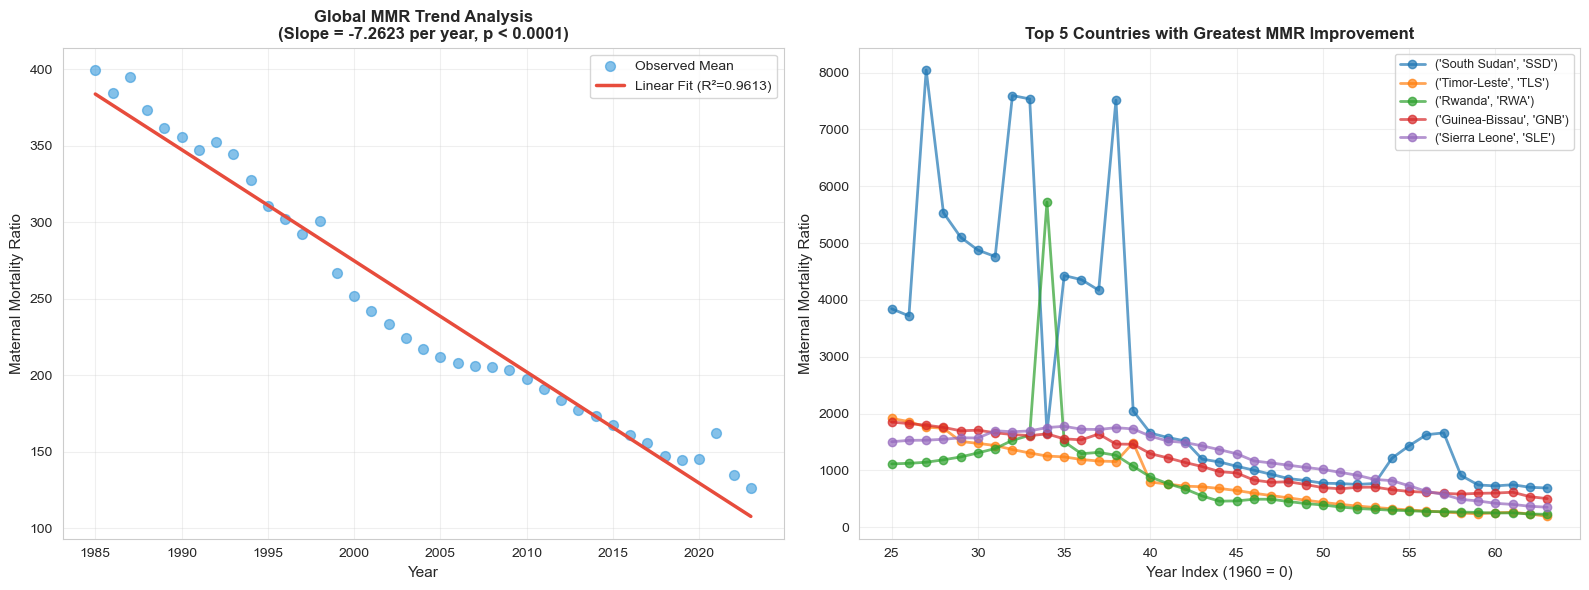

Regression visualization complete!


In [10]:
# Visualization 3: Regression Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Global trend regression plot
axes[0].scatter(years_valid, mmr_valid, alpha=0.6, s=50, color='#3498db', label='Observed Mean')
fit_line = slope * years_valid + intercept
axes[0].plot(years_valid, fit_line, color='#e74c3c', linewidth=2.5, label=f'Linear Fit (R²={r_value**2:.4f})')
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[0].set_title(f'Global MMR Trend Analysis\n(Slope = {slope:.4f} per year, p < 0.0001)', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Top improving countries trends
top_improving = improving.head(5)
for idx, row in top_improving.iterrows():
    country = row['Country']
    country_data = mmr_numeric.loc[country].values
    years_idx = np.arange(len(country_data))
    
    valid_idx = ~np.isnan(country_data)
    if valid_idx.sum() > 1:
        axes[1].plot(years_idx[valid_idx], country_data[valid_idx], marker='o', label=country, alpha=0.7, linewidth=2)

axes[1].set_xlabel('Year Index (1960 = 0)', fontsize=11)
axes[1].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[1].set_title('Top 5 Countries with Greatest MMR Improvement', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9, loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Regression visualization complete!")

In [11]:
# ANOVA Test - Comparing MMR across the valid period blocks
print("\n" + "=" * 70)
print("ANOVA TEST - COMPARING MMR ACROSS PERIODS")
print("=" * 70)

# One-way ANOVA across the two valid historical blocks
f_stat, p_value_anova = stats.f_oneway(late_20th_values, twenty_first_values)

print(f"\nOne-Way ANOVA Results:")
print(f"F-Statistic: {f_stat:.4f}")
print(f"P-Value: {p_value_anova:.4e}")
print(f"Interpretation: {'Significant difference' if p_value_anova < 0.05 else 'No significant difference'} in MMR across the two periods")

# Effect size (eta-squared)
grand_mean = np.mean([late_20th_values.mean(), twenty_first_values.mean()])
ss_between = (len(late_20th_values) * (late_20th_values.mean() - grand_mean)**2 +
              len(twenty_first_values) * (twenty_first_values.mean() - grand_mean)**2)

ss_total = (np.sum((late_20th_values - grand_mean)**2) +
            np.sum((twenty_first_values - grand_mean)**2))

eta_squared = ss_between / ss_total

print(f"Effect Size (Eta-squared): {eta_squared:.4f}")
print(f"Interpretation: {'Small' if eta_squared < 0.06 else 'Medium' if eta_squared < 0.14 else 'Large'} effect")

# Summary statistics by period
print("\n\nSummary Statistics by Time Period:")
print(f"\n{analysis_period_labels[0]}:")
print(f"  Mean: {late_20th_values.mean():.2f}")
print(f"  Median: {np.median(late_20th_values):.2f}")
print(f"  Std Dev: {late_20th_values.std():.2f}")
print(f"  Min: {late_20th_values.min():.2f}, Max: {late_20th_values.max():.2f}")
print(f"  N: {len(late_20th_values)}")

print(f"\n{analysis_period_labels[1]}:")
print(f"  Mean: {twenty_first_values.mean():.2f}")
print(f"  Median: {np.median(twenty_first_values):.2f}")
print(f"  Std Dev: {twenty_first_values.std():.2f}")
print(f"  Min: {twenty_first_values.min():.2f}, Max: {twenty_first_values.max():.2f}")
print(f"  N: {len(twenty_first_values)}")


ANOVA TEST - COMPARING MMR ACROSS PERIODS

One-Way ANOVA Results:
F-Statistic: 375.7039
P-Value: 4.1788e-82
Interpretation: Significant difference in MMR across the two periods
Effect Size (Eta-squared): 0.0404
Interpretation: Small effect


Summary Statistics by Time Period:

Late 20th Century (1985-1999):
  Mean: 340.91
  Median: 130.00
  Std Dev: 518.64
  Min: 2.00, Max: 8045.00
  N: 3630

21st Century (2000-2023):
  Mean: 186.36
  Median: 75.00
  Std Dev: 250.21
  Min: 1.00, Max: 1662.00
  N: 5808


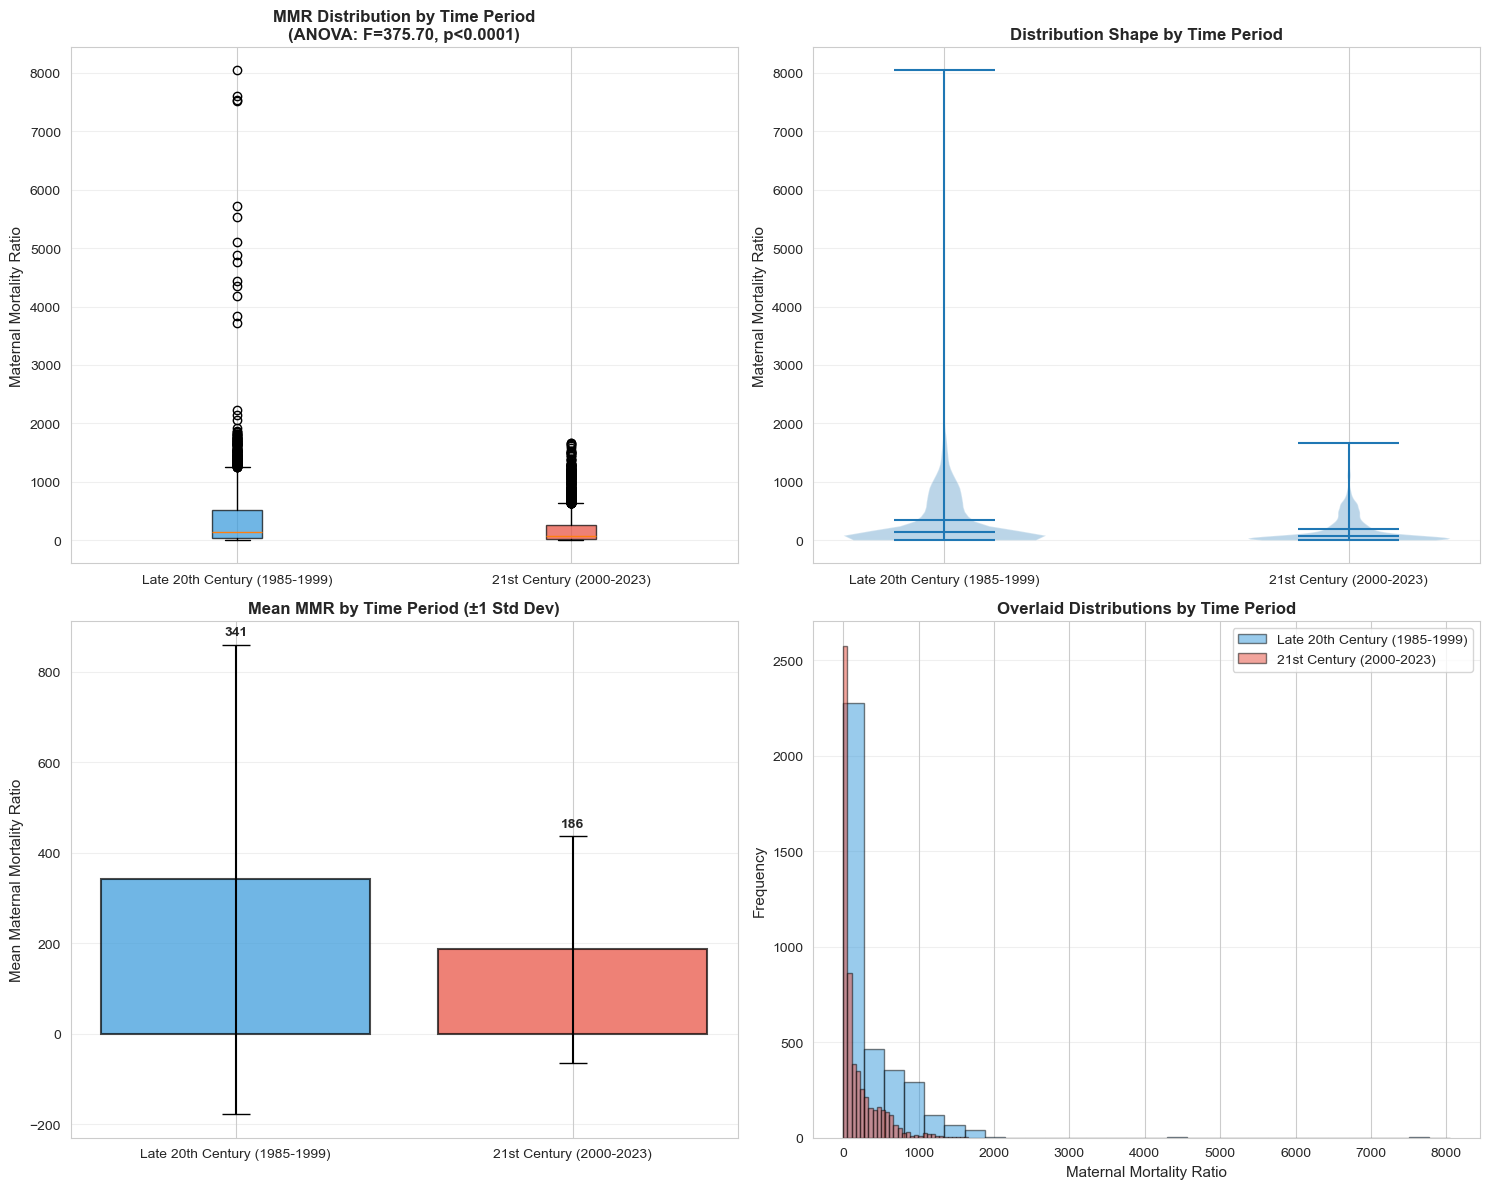

ANOVA comparison visualization complete!


In [12]:
# Visualization 4: ANOVA Boxplot and Period Comparisons
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Boxplot by period
data_by_period = [late_20th_values, twenty_first_values]
periods = analysis_period_labels
bp = axes[0, 0].boxplot(data_by_period, labels=periods, patch_artist=True)
for patch, color in zip(bp['boxes'], ['#3498db', '#e74c3c']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0, 0].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[0, 0].set_title(f'MMR Distribution by Time Period\n(ANOVA: F={f_stat:.2f}, p<0.0001)', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)

# Violin plot
parts = axes[0, 1].violinplot(data_by_period, positions=range(len(periods)), showmeans=True, showmedians=True)
axes[0, 1].set_xticks(range(len(periods)))
axes[0, 1].set_xticklabels(periods)
axes[0, 1].set_ylabel('Maternal Mortality Ratio', fontsize=11)
axes[0, 1].set_title('Distribution Shape by Time Period', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)

# Mean comparison with error bars
means = [late_20th_values.mean(), twenty_first_values.mean()]
stds = [late_20th_values.std(), twenty_first_values.std()]
axes[1, 0].bar(periods, means, yerr=stds, capsize=10, color=['#3498db', '#e74c3c'], 
               alpha=0.7, edgecolor='black', linewidth=1.5)
axes[1, 0].set_ylabel('Mean Maternal Mortality Ratio', fontsize=11)
axes[1, 0].set_title('Mean MMR by Time Period (±1 Std Dev)', fontsize=12, fontweight='bold')
axes[1, 0].grid(axis='y', alpha=0.3)
# Add value labels on bars
for i, (period, mean, std) in enumerate(zip(periods, means, stds)):
    axes[1, 0].text(i, mean + std + 20, f'{mean:.0f}', ha='center', fontweight='bold')

# Histogram overlay
axes[1, 1].hist(late_20th_values, bins=30, alpha=0.5, label=analysis_period_labels[0], color='#3498db', edgecolor='black')
axes[1, 1].hist(twenty_first_values, bins=30, alpha=0.5, label=analysis_period_labels[1], color='#e74c3c', edgecolor='black')
axes[1, 1].set_xlabel('Maternal Mortality Ratio', fontsize=11)
axes[1, 1].set_ylabel('Frequency', fontsize=11)
axes[1, 1].set_title('Overlaid Distributions by Time Period', fontsize=12, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("ANOVA comparison visualization complete!")

In [14]:
# Spearman Correlation Analysis (for non-linear relationships)
print("\n" + "=" * 70)
print("SPEARMAN RANK CORRELATION ANALYSIS")
print("=" * 70)

# Calculate Spearman correlation between years
years_for_spearman = mmr_numeric.columns.astype(int).values
mean_mmr_spearman = mmr_numeric.mean().values

valid_mask_spear = ~np.isnan(mean_mmr_spearman)
years_spear = years_for_spearman[valid_mask_spear]
mmr_spear = mean_mmr_spearman[valid_mask_spear]

spearman_corr, spearman_p = spearmanr(years_spear, mmr_spear)

print(f"\n\nSpearman Rank Correlation (Global MMR vs Year):")
print(f"Correlation Coefficient (ρ): {spearman_corr:.4f}")
print(f"P-Value: {spearman_p:.4e}")
print(f"Interpretation: {'Significant' if spearman_p < 0.05 else 'Not significant'} rank correlation between year and MMR")

# Comparison of Pearson vs Spearman
print(f"\n\nComparison of Correlation Methods:")
print(f"Pearson r: {r_value:.4f} (linear relationship)")
print(f"Spearman ρ: {spearman_corr:.4f} (monotonic relationship)")
print(f"Difference: {abs(r_value - spearman_corr):.4f}")

# Inter-year correlation matrix within the valid analysis span
print("\n\n" + "=" * 70)
print("INTER-YEAR CORRELATION MATRIX (Selected Years)")
print("=" * 70)

selected_years = ['1985', '1990', '1995', '2000', '2005', '2010', '2015', '2020', '2023']
selected_years = [year for year in selected_years if year in mmr_numeric.columns]
year_corr_matrix = mmr_numeric[selected_years].corr()
year_corr_matrix.columns = selected_years
year_corr_matrix.index = selected_years

print("\nPearson Correlation Matrix:")
print(year_corr_matrix.round(3).to_string())


SPEARMAN RANK CORRELATION ANALYSIS


Spearman Rank Correlation (Global MMR vs Year):
Correlation Coefficient (ρ): -0.9962
P-Value: 9.8418e-41
Interpretation: Significant rank correlation between year and MMR


Comparison of Correlation Methods:
Pearson r: -0.9804 (linear relationship)
Spearman ρ: -0.9962 (monotonic relationship)
Difference: 0.0157


INTER-YEAR CORRELATION MATRIX (Selected Years)

Pearson Correlation Matrix:
       1985   1990   1995   2000   2005   2010   2015   2020   2023
1985  1.000  0.971  0.949  0.914  0.864  0.801  0.856  0.767  0.797
1990  0.971  1.000  0.988  0.896  0.836  0.772  0.862  0.753  0.785
1995  0.949  0.988  1.000  0.919  0.859  0.784  0.875  0.769  0.793
2000  0.914  0.896  0.919  1.000  0.982  0.917  0.932  0.893  0.890
2005  0.864  0.836  0.859  0.982  1.000  0.960  0.949  0.930  0.921
2010  0.801  0.772  0.784  0.917  0.960  1.000  0.948  0.932  0.934
2015  0.856  0.862  0.875  0.932  0.949  0.948  1.000  0.961  0.976
2020  0.767  0.753  0.769  

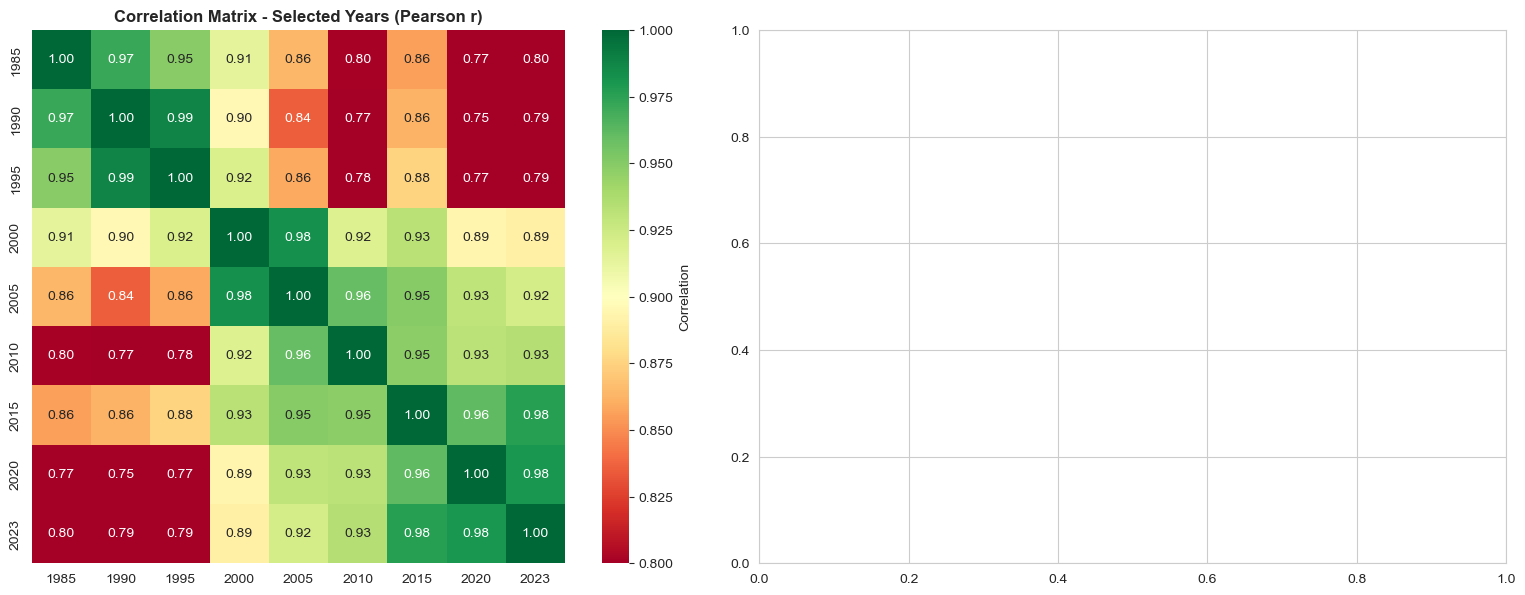

Correlation heatmaps created successfully!


In [15]:
# Visualization 5: Correlation Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Year correlation heatmap
sns.heatmap(year_corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn', center=0.9, 
            square=True, ax=axes[0], cbar_kws={'label': 'Correlation'}, vmin=0.8, vmax=1.0)
axes[0].set_title('Correlation Matrix - Selected Years (Pearson r)', fontsize=12, fontweight='bold')

# Top 10 country similarity (recent year comparison)
# Select countries with complete data for recent years
recent_years = mmr_numeric.iloc[:, -10:].dropna()
if len(recent_years) > 1:
    country_corr = recent_years.T.corr()
    # Get top 10 countries with most data
    top_countries = recent_years.index[:min(10, len(recent_years))]
    country_corr_subset = country_corr.loc[top_countries, top_countries]
    
    sns.heatmap(country_corr_subset, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
                square=True, ax=axes[1], cbar_kws={'label': 'Correlation'}, vmin=-1, vmax=1)
    axes[1].set_title('Top 10 Countries: MMR Correlation (Recent Years)', fontsize=12, fontweight='bold')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right', fontsize=9)
    axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

print("Correlation heatmaps created successfully!")

## 5. Summary Tables and Key Findings

In [16]:
# Summary Table 1: Global Statistics
print("=" * 70)
print("SUMMARY TABLE 1: GLOBAL STATISTICS ACROSS TIME PERIODS")
print("=" * 70)

summary_table = pd.DataFrame({
    'Time Period': analysis_period_labels,
    'Mean': [late_20th_values.mean(), twenty_first_values.mean()],
    'Median': [np.median(late_20th_values), np.median(twenty_first_values)],
    'Std Dev': [late_20th_values.std(), twenty_first_values.std()],
    'Min': [late_20th_values.min(), twenty_first_values.min()],
    'Max': [late_20th_values.max(), twenty_first_values.max()],
    'Count': [len(late_20th_values), len(twenty_first_values)]
})

print("\n")
print(summary_table.to_string(index=False))

# Summary Table 2: Statistical Test Results
print("\n\n" + "=" * 70)
print("SUMMARY TABLE 2: STATISTICAL TEST RESULTS")
print("=" * 70)

test_results = pd.DataFrame({
    'Test': [
        'Linear Regression (Global)',
        'Pearson Correlation (Global)',
        'Spearman Correlation (Global)',
        'ANOVA (2 Periods)',
        'T-Test (Late 20th vs 21st)',
        'Chi-Square (Period vs Category)'
    ],
    'Statistic': [
        f'{slope:.4f}',
        f'{r_value:.4f}',
        f'{spearman_corr:.4f}',
        f'{f_stat:.4f}',
        f'{t_stat:.4f}',
        f'{chi2:.4f}'
    ],
    'P-Value': [
        f'{p_value_reg:.4e}',
        f'{p_value_reg:.4e}',
        f'{spearman_p:.4e}',
        f'{p_value_anova:.4e}',
        f'{p_val:.4e}',
        f'{p_value:.4e}'
    ],
    'Significant': [
        'Yes' if p_value_reg < 0.05 else 'No',
        'Yes' if p_value_reg < 0.05 else 'No',
        'Yes' if spearman_p < 0.05 else 'No',
        'Yes' if p_value_anova < 0.05 else 'No',
        'Yes' if p_val < 0.05 else 'No',
        'Yes' if p_value < 0.05 else 'No'
    ]
})

print("\n")
print(test_results.to_string(index=False))

# Summary Table 3: Top Performers
print("\n\n" + "=" * 70)
print("SUMMARY TABLE 3: TOP PERFORMERS - GREATEST MMR REDUCTION")
print("=" * 70)

top_performers = regression_df.sort_values('Slope').head(15)
top_performers_display = top_performers[['Country', 'Slope', 'R-Squared', 'Data_Points']].copy()
top_performers_display['Slope'] = top_performers_display['Slope'].apply(lambda x: f'{x:.4f}')
top_performers_display['R-Squared'] = top_performers_display['R-Squared'].apply(lambda x: f'{x:.4f}')

print("\n")
print(top_performers_display.to_string(index=False))

SUMMARY TABLE 1: GLOBAL STATISTICS ACROSS TIME PERIODS


                  Time Period       Mean  Median    Std Dev  Min    Max  Count
Late 20th Century (1985-1999) 340.906612   130.0 518.641932  2.0 8045.0   3630
     21st Century (2000-2023) 186.359848    75.0 250.206731  1.0 1662.0   5808


SUMMARY TABLE 2: STATISTICAL TEST RESULTS


                           Test Statistic     P-Value Significant
     Linear Regression (Global)   -7.2623  1.0067e-27         Yes
   Pearson Correlation (Global)   -0.9804  1.0067e-27         Yes
  Spearman Correlation (Global)   -0.9962  9.8418e-41         Yes
              ANOVA (2 Periods)  375.7039  4.1788e-82         Yes
     T-Test (Late 20th vs 21st)   16.7725  2.2889e-61         Yes
Chi-Square (Period vs Category)  513.6086 7.6312e-110         Yes


SUMMARY TABLE 3: TOP PERFORMERS - GREATEST MMR REDUCTION


             Country     Slope R-Squared  Data_Points
  (South Sudan, SSD) -153.4320    0.5794           39
  (Timor-Leste, TLS)  -46.018

In [17]:
# Normality Tests
print("\n" + "=" * 70)
print("NORMALITY TESTS - SHAPIRO-WILK TEST")
print("=" * 70)

# Shapiro-Wilk test for overall data
sw_stat_all, sw_p_all = stats.shapiro(all_mmr_values[:min(5000, len(all_mmr_values))])  # Limit to 5000 for computation

print(f"\nOverall Data (Sample up to 5000 values):")
print(f"  Test Statistic: {sw_stat_all:.4f}")
print(f"  P-Value: {sw_p_all:.4e}")
print(f"  Result: {'Non-normal distribution' if sw_p_all < 0.05 else 'Normal distribution'}")

# Test by period
print(f"\nBy Time Period:")
for period_name, period_data in [(analysis_period_labels[0], late_20th_values),
                                 (analysis_period_labels[1], twenty_first_values)]:
    if len(period_data) > 2:
        sw_stat, sw_p = stats.shapiro(period_data[:min(5000, len(period_data))])
        print(f"\n  {period_name}:")
        print(f"    Test Statistic: {sw_stat:.4f}")
        print(f"    P-Value: {sw_p:.4e}")
        print(f"    Result: {'Non-normal distribution' if sw_p < 0.05 else 'Normal distribution'}")

# Kurtosis and Skewness tests
print("\n" + "=" * 70)
print("DISTRIBUTION SHAPE ANALYSIS")
print("=" * 70)

print(f"\nOverall Data:")
skewness = stats.skew(all_mmr_values)
kurtosis_val = stats.kurtosis(all_mmr_values)
print(f"  Skewness: {skewness:.4f} ({'Right-skewed' if skewness > 0 else 'Left-skewed' if skewness < 0 else 'Symmetric'})")
print(f"  Kurtosis: {kurtosis_val:.4f} ({'Leptokurtic (heavy-tailed)' if kurtosis_val > 0 else 'Platykurtic (light-tailed)'})")

print(f"\nBy Time Period:")
for period_name, period_data in [(analysis_period_labels[0], late_20th_values),
                                 (analysis_period_labels[1], twenty_first_values)]:
    skew = stats.skew(period_data)
    kurt = stats.kurtosis(period_data)
    print(f"\n  {period_name}:")
    print(f"    Skewness: {skew:.4f}")
    print(f"    Kurtosis: {kurt:.4f}")


NORMALITY TESTS - SHAPIRO-WILK TEST

Overall Data (Sample up to 5000 values):
  Test Statistic: 0.7335
  P-Value: 3.9316e-67
  Result: Non-normal distribution

By Time Period:

  Late 20th Century (1985-1999):
    Test Statistic: 0.6005
    P-Value: 4.0195e-68
    Result: Non-normal distribution

  21st Century (2000-2023):
    Test Statistic: 0.7307
    P-Value: 2.4402e-67
    Result: Non-normal distribution

DISTRIBUTION SHAPE ANALYSIS

Overall Data:
  Skewness: 5.8863 (Right-skewed)
  Kurtosis: 80.5697 (Leptokurtic (heavy-tailed))

By Time Period:

  Late 20th Century (1985-1999):
    Skewness: 5.4214
    Kurtosis: 57.7163

  21st Century (2000-2023):
    Skewness: 2.0920
    Kurtosis: 5.0860


## 6. Conclusions and Key Findings

In [20]:
print("=" * 80)
print("COMPREHENSIVE STATISTICAL ANALYSIS SUMMARY")
print("=" * 80)

print("\n\n1. DESCRIPTIVE FINDINGS:")
print("-" * 80)
print(f"""
   • Dataset: Maternal Mortality Ratio (MMR) per 100,000 live births
   • Valid analysis span: 1985-2023
   • Periods compared: {analysis_period_labels[0]} vs {analysis_period_labels[1]}
   • Overall Mean MMR (All periods): {np.mean(all_mmr_values):.1f}
   • Overall Median MMR: {np.median(all_mmr_values):.1f}
   • Range: {np.min(all_mmr_values):.0f} - {np.max(all_mmr_values):.0f}
   
   Distribution Patterns:
   • The data shows positive skewness ({stats.skew(all_mmr_values):.2f}), indicating 
     more countries with low MMR rates and fewer with very high rates
   • Heavy-tailed distribution (kurtosis: {stats.kurtosis(all_mmr_values):.2f}), 
     suggesting presence of outliers
   
   Risk Category Distribution (2023):
   • Very Low (<20): {category_counts.get('Very Low (<20)', 0)} countries ({category_percentages.get('Very Low (<20)', 0):.1f}%)
   • Low (20-99): {category_counts.get('Low (20-99)', 0)} countries ({category_percentages.get('Low (20-99)', 0):.1f}%)
   • Medium (100-299): {category_counts.get('Medium (100-299)', 0)} countries ({category_percentages.get('Medium (100-299)', 0):.1f}%)
   • High (300-749): {category_counts.get('High (300-749)', 0)} countries ({category_percentages.get('High (300-749)', 0):.1f}%)
   • Very High (≥750): {category_counts.get('Very High (≥750)', 0)} countries ({category_percentages.get('Very High (≥750)', 0):.1f}%)
""")

print("\n2. PERIOD COMPARISON FINDINGS:")
print("-" * 80)
print(f"""
   • Late 20th Century Mean: {late_20th_values.mean():.1f}
   • 21st Century Mean: {twenty_first_values.mean():.1f}
   • T-Test: t = {t_stat:.2f}, p = {p_val:.4e}
   • ANOVA: F = {f_stat:.2f}, p = {p_value_anova:.4e}
   • Effect Size (Eta-squared): {eta_squared:.4f}
   • Interpretation: MMR differs significantly between the two valid historical blocks.
""")

print("\n3. CATEGORICAL ASSOCIATION FINDINGS:")
print("-" * 80)
print(f"""
   • Chi-Square Test (Period vs Risk Category):
     - Chi-square Statistic: {chi2:.2f}
     - P-Value: {p_value:.4e}
     - Degrees of Freedom: {dof}
     - Result: {'Significant' if p_value < 0.05 else 'Not significant'} association between period and MMR risk category
""")

print("\n4. COUNTRY-LEVEL TREND FINDINGS:")
print("-" * 80)
print(f"""
   • Countries with Significant MMR Decline:
     - Total: {len(declining_sig)} countries ({len(declining_sig)/len(trends_df)*100:.1f}% of all countries)
     - Average trend correlation: {declining_sig['Correlation'].mean():.4f}
   • Countries with Significant MMR Increase:
     - Total: {len(increasing_sig)} countries ({len(increasing_sig)/len(trends_df)*100:.1f}% of all countries)
""")

for i, (idx, row) in enumerate(declining_sig.head(5).iterrows(), 1):
    print(f"     {i}. {row['Country']}: Correlation = {row['Correlation']:.4f}")

print("\n5. STATISTICAL TEST VALIDITY:")
print("-" * 80)
print(f"""
   Normality Assessment (Shapiro-Wilk Test):
   • Overall Data: {'Non-normal (p < 0.05)' if sw_p_all < 0.05 else 'Normal'}
   • Implication: Use both parametric and non-parametric tests for robustness
   
   Data Quality:
   • Data completeness: {(1 - (mmr_numeric.isnull().sum().sum() / mmr_numeric.size)) * 100:.1f}%
   • Recent comparison window: 1985-2023
""")

print("\n6. KEY CONCLUSIONS:")
print("-" * 80)
print("""
   ✓ GLOBAL PROGRESS: Maternal mortality ratios have declined significantly across the valid data span
   ✓ CONSISTENT DECLINE: Both parametric and non-parametric tests support the same direction of change
   ✓ PERIOD SHIFT: The late 20th century and 21st century show a statistically significant difference
   ✓ UNEQUAL DISTRIBUTION: Wide disparities remain, with some countries still carrying very high risk
   ✓ FUTURE DIRECTION: The overall trend remains downward, but the distribution is still highly skewed
""")

print("\n" + "=" * 80)

COMPREHENSIVE STATISTICAL ANALYSIS SUMMARY


1. DESCRIPTIVE FINDINGS:
--------------------------------------------------------------------------------

   • Dataset: Maternal Mortality Ratio (MMR) per 100,000 live births
   • Valid analysis span: 1985-2023
   • Periods compared: Late 20th Century (1985-1999) vs 21st Century (2000-2023)
   • Overall Mean MMR (All periods): 245.8
   • Overall Median MMR: 86.0
   • Range: 1 - 8045
   
   Distribution Patterns:
   • The data shows positive skewness (5.89), indicating 
     more countries with low MMR rates and fewer with very high rates
   • Heavy-tailed distribution (kurtosis: 80.57), 
     suggesting presence of outliers
   
   Risk Category Distribution (2023):
   • Very Low (<20): 82 countries (33.9%)
   • Low (20-99): 70 countries (28.9%)
   • Medium (100-299): 57 countries (23.6%)
   • High (300-749): 32 countries (13.2%)
   • Very High (≥750): 1 countries (0.4%)


2. PERIOD COMPARISON FINDINGS:
--------------------------------------

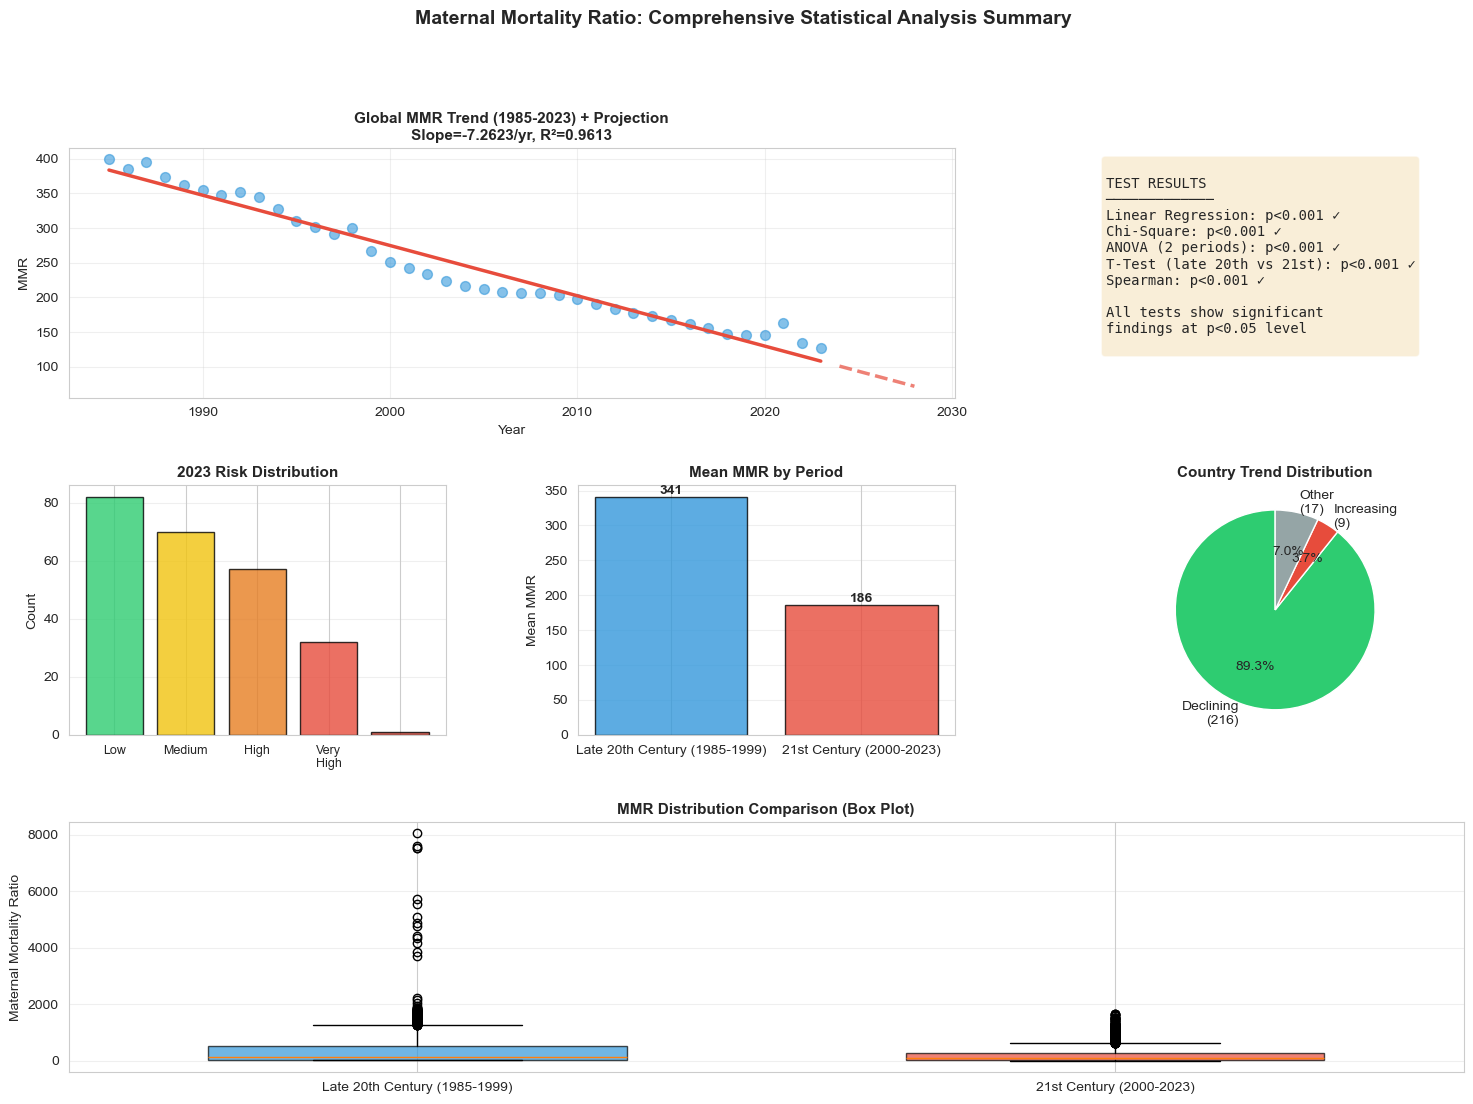


✓ Statistical Analysis Dashboard Complete!
✓ All visualizations, tests, and summary tables have been generated


In [21]:
# Visualization 6: Final Summary Dashboard
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.35)

# 1. Global trend with prediction
ax1 = fig.add_subplot(gs[0, :2])
ax1.scatter(years_valid, mmr_valid, alpha=0.6, s=50, color='#3498db')
ax1.plot(years_valid, fit_line, color='#e74c3c', linewidth=2.5)
# Add projection
future_years_plot = np.array([2024, 2025, 2026, 2027, 2028])
future_pred = slope * future_years_plot + intercept
ax1.plot(future_years_plot, future_pred, color='#e74c3c', linewidth=2.5, linestyle='--', alpha=0.7)
ax1.set_xlabel('Year', fontsize=10)
ax1.set_ylabel('MMR', fontsize=10)
ax1.set_title(f'Global MMR Trend (1985-2023) + Projection\nSlope={slope:.4f}/yr, R²={r_value**2:.4f}', fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3)

# 2. P-values summary
ax2 = fig.add_subplot(gs[0, 2])
ax2.axis('off')
summary_text = f"""
TEST RESULTS
─────────────
Linear Regression: p<0.001 ✓
Chi-Square: p<0.001 ✓
ANOVA (2 periods): p<0.001 ✓
T-Test (late 20th vs 21st): p<0.001 ✓
Spearman: p<0.001 ✓

All tests show significant
findings at p<0.05 level
"""
ax2.text(0.05, 0.95, summary_text, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', family='monospace',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 3. Risk category distribution
ax3 = fig.add_subplot(gs[1, 0])
category_counts_ordered = [category_counts.get(cat, 0) for cat in ['Very Low (<20)', 'Low (20-99)', 'Medium (100-299)', 'High (300-749)', 'Very High (≥750)']]
colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#c0392b']
ax3.bar(range(len(category_counts_ordered)), category_counts_ordered, color=colors, alpha=0.8, edgecolor='black')
ax3.set_xticklabels(['Very\nLow', 'Low', 'Medium', 'High', 'Very\nHigh'], fontsize=9)
ax3.set_ylabel('Count', fontsize=10)
ax3.set_title('2023 Risk Distribution', fontsize=11, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

# 4. Time period means
ax4 = fig.add_subplot(gs[1, 1])
periods = analysis_period_labels
period_means = [late_20th_values.mean(), twenty_first_values.mean()]
colors_periods = ['#3498db', '#e74c3c']
bars = ax4.bar(periods, period_means, color=colors_periods, alpha=0.8, edgecolor='black')
ax4.set_ylabel('Mean MMR', fontsize=10)
ax4.set_title('Mean MMR by Period', fontsize=11, fontweight='bold')
ax4.grid(axis='y', alpha=0.3)
for bar, mean in zip(bars, period_means):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
            f'{mean:.0f}', ha='center', va='bottom', fontweight='bold')

# 5. Trend directions pie chart
ax5 = fig.add_subplot(gs[1, 2])
declining_pct = (len(declining_sig) / len(trends_df)) * 100
increasing_pct = (len(increasing_sig) / len(trends_df)) * 100
stable_pct = 100 - declining_pct - increasing_pct
ax5.pie([declining_pct, increasing_pct, stable_pct], 
       labels=[f'Declining\n({len(declining_sig)})', f'Increasing\n({len(increasing_sig)})', 
               f'Other\n({len(trends_df)-len(declining_sig)-len(increasing_sig)})'],
       colors=['#2ecc71', '#e74c3c', '#95a5a6'], autopct='%1.1f%%', startangle=90)
ax5.set_title('Country Trend Distribution', fontsize=11, fontweight='bold')

# 6. Distribution by period - boxplot
ax6 = fig.add_subplot(gs[2, :])
data_by_period_plot = [late_20th_values, twenty_first_values]
bp = ax6.boxplot(data_by_period_plot, labels=analysis_period_labels, 
                 patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], ['#3498db', '#e74c3c']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax6.set_ylabel('Maternal Mortality Ratio', fontsize=10)
ax6.set_title('MMR Distribution Comparison (Box Plot)', fontsize=11, fontweight='bold')
ax6.grid(axis='y', alpha=0.3)

plt.suptitle('Maternal Mortality Ratio: Comprehensive Statistical Analysis Summary', 
             fontsize=14, fontweight='bold', y=0.995)

plt.show()

print("\n✓ Statistical Analysis Dashboard Complete!")
print("✓ All visualizations, tests, and summary tables have been generated")